In [11]:
!nvidia-smi
import torch
print(torch.__version__, "| GPU available:", torch.cuda.is_available())

Thu Oct 29 11:05:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!mkdir -p /content/rsna
!kaggle competitions download -c rsna-pneumonia-detection-challenge -p /content/rsna
!unzip -q /content/rsna/rsna-pneumonia-detection-challenge.zip -d /content/rsna
!ls /content/rsna
!ls /content/rsna/stage_2_train_images | wc -l

100% 3.66G/3.66G [02:50<00:00, 23.0MB/s]

'GCP Credits Request Link - RSNA.txt'	  stage_2_test_images
 rsna-pneumonia-detection-challenge.zip   stage_2_train_images
 stage_2_detailed_class_info.csv	  stage_2_train_labels.csv
 stage_2_sample_submission.csv
26684


In [17]:
import os, subprocess
from pathlib import Path
from google.colab import drive, userdata

# 1. Mount Drive (click Allow if asked)
if not os.path.ismount("/content/drive"):
    drive.mount('/content/drive')
else:
    print("Drive already mounted")

# 2. Kaggle login + libraries
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
subprocess.run("pip -q install kaggle pydicom", shell=True, check=True)

# 3. Download + unzip only if the data is missing
if not Path("/content/rsna/stage_2_train_labels.csv").exists():
    subprocess.run("mkdir -p /content/rsna", shell=True, check=True)
    subprocess.run("kaggle competitions download -c rsna-pneumonia-detection-challenge -p /content/rsna", shell=True, check=True)
    subprocess.run("unzip -q /content/rsna/rsna-pneumonia-detection-challenge.zip -d /content/rsna", shell=True, check=True)

print("Train images:", len(list(Path("/content/rsna/stage_2_train_images").glob("*.dcm"))))

Drive already mounted
Train images: 26684


In [18]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import os
import numpy as np
import pandas as pd
import pydicom
from PIL import Image
from sklearn.model_selection import train_test_split

RAW = Path("/content/rsna")
OUT = Path("/content/drive/MyDrive/ai-medical-imaging/cache")
assert os.path.ismount("/content/drive"), "Drive is NOT mounted. Run the setup cell first!"
OUT.mkdir(parents=True, exist_ok=True)
SIZE = 224

# Same split code as on your laptop (same seed), so the splits match
labels = pd.read_csv(RAW / "stage_2_train_labels.csv")
patients = (labels.groupby("patientId")["Target"].max()
            .reset_index().rename(columns={"Target": "label"}))
train, temp = train_test_split(patients, test_size=0.30,
                               stratify=patients.label, random_state=42)
val, test = train_test_split(temp, test_size=0.50,
                             stratify=temp.label, random_state=42)


def load(pid):
    ds = pydicom.dcmread(RAW / "stage_2_train_images" / f"{pid}.dcm")
    img = ds.pixel_array.astype(np.float32)
    if ds.PhotometricInterpretation == "MONOCHROME1":
        img = img.max() - img
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    img = Image.fromarray((img * 255).astype(np.uint8))
    return np.array(img.resize((SIZE, SIZE), Image.BILINEAR))


for name, df in [("train", train), ("val", val), ("test", test)]:
    with ThreadPoolExecutor(8) as ex:
        X = np.stack(list(ex.map(load, df.patientId)))
    np.save(OUT / f"X_{name}.npy", X)
    np.save(OUT / f"y_{name}.npy", df.label.values.astype(np.float32))
    df.to_csv(OUT / f"{name}_ids.csv", index=False)
    print(name, X.shape, "| pneumonia rate:", round(df.label.mean(), 3))

train (18678, 224, 224) | pneumonia rate: 0.225
val (4003, 224, 224) | pneumonia rate: 0.225
test (4003, 224, 224) | pneumonia rate: 0.225


In [19]:
import os, json, time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from google.colab import drive

if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
assert os.path.ismount("/content/drive"), "Drive is NOT mounted!"

BASE = Path("/content/drive/MyDrive/ai-medical-imaging")
CACHE, MODELS, RESULTS = BASE / "cache", BASE / "models", BASE / "results"
MODELS.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)

X = {s: np.load(CACHE / f"X_{s}.npy") for s in ["train", "val", "test"]}
y = {s: np.load(CACHE / f"y_{s}.npy") for s in ["train", "val", "test"]}
for s in X:
    print(s, X[s].shape, X[s].dtype, "| pneumonia rate:", round(float(y[s].mean()), 3))

device = torch.device("cuda")
print("Device:", torch.cuda.get_device_name(0))

train (18678, 224, 224) uint8 | pneumonia rate: 0.225
val (4003, 224, 224) uint8 | pneumonia rate: 0.225
test (4003, 224, 224) uint8 | pneumonia rate: 0.225
Device: Tesla T4


In [20]:
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.ToPILImage(),
    T.RandomAffine(degrees=7, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.Grayscale(num_output_channels=3),
    T.ToTensor(), T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([
    T.ToPILImage(), T.Grayscale(num_output_channels=3),
    T.ToTensor(), T.Normalize(MEAN, STD),
])

class XrayDataset(Dataset):
    def __init__(self, images, labels, tf):
        self.images, self.labels, self.tf = images, labels, tf
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        return self.tf(self.images[i]), torch.tensor(self.labels[i])

BATCH = 64
def make_loader(split, tf, shuffle):
    return DataLoader(XrayDataset(X[split], y[split], tf), batch_size=BATCH,
                      shuffle=shuffle, num_workers=2, pin_memory=True,
                      persistent_workers=True)

train_loader = make_loader("train", train_tf, True)
val_loader = make_loader("val", eval_tf, False)
test_loader = make_loader("test", eval_tf, False)

xb, yb = next(iter(train_loader))
print("Batch:", tuple(xb.shape), "| labels:", tuple(yb.shape))

Batch: (64, 3, 224, 224) | labels: (64,)


In [21]:
from torchvision import models
from sklearn.metrics import roc_auc_score

model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
model.classifier = nn.Linear(model.classifier.in_features, 1)  # 1 output: pneumonia or not
model = model.to(device)

# Normal cases outnumber pneumonia ~3.4:1, so we weight the positive class
pos_weight = torch.tensor([(y["train"] == 0).sum() / (y["train"] == 1).sum()]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
scaler = torch.amp.GradScaler("cuda")


@torch.no_grad()
def predict(loader):
    model.eval()
    probs, labels = [], []
    for xb, yb in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(xb.to(device, non_blocking=True))
        probs.append(torch.sigmoid(out.float()).squeeze(1).cpu())
        labels.append(yb)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()


def train_one_epoch(optimizer, backbone_frozen):
    model.train()
    if backbone_frozen:
        model.features.eval()   # keep BatchNorm statistics fixed while frozen
    total = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        optimizer.zero_grad()
        with torch.autocast("cuda", dtype=torch.float16):
            loss = criterion(model(xb).squeeze(1), yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * len(xb)
    return total / len(train_loader.dataset)


history = []
best_auc, bad_epochs, PATIENCE = 0.0, 0, 3
FROZEN_EPOCHS, TOTAL_EPOCHS = 2, 10

for epoch in range(1, TOTAL_EPOCHS + 1):
    t0 = time.time()
    frozen = epoch <= FROZEN_EPOCHS

    if epoch == 1 or epoch == FROZEN_EPOCHS + 1:   # (re)build optimizer at each phase
        for p in model.features.parameters():
            p.requires_grad = not frozen
        params = [p for p in model.parameters() if p.requires_grad]
        optimizer = torch.optim.AdamW(params, lr=1e-3 if frozen else 1e-4, weight_decay=1e-4)
        if not frozen:
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=TOTAL_EPOCHS - FROZEN_EPOCHS)

    train_loss = train_one_epoch(optimizer, frozen)
    if not frozen:
        scheduler.step()

    vp, vl = predict(val_loader)
    val_loss = float(criterion(torch.logit(torch.tensor(vp).clamp(1e-6, 1 - 1e-6)).to(device),
                               torch.tensor(vl).to(device)))
    val_auc = roc_auc_score(vl, vp)
    val_acc = float(((vp > 0.5) == vl).mean())
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                        val_auc=val_auc, val_acc=val_acc))

    saved = ""
    if val_auc > best_auc:
        best_auc, bad_epochs, saved = val_auc, 0, "  <- best, saved"
        torch.save(model.state_dict(), MODELS / "best_model.pt")
    else:
        bad_epochs += 1
    json.dump(history, open(RESULTS / "history.json", "w"))

    print(f"Epoch {epoch:2d}/{TOTAL_EPOCHS} {'(frozen)' if frozen else '(tuning)'} | "
          f"train loss {train_loss:.3f} | val loss {val_loss:.3f} | "
          f"val AUC {val_auc:.3f} | val acc {val_acc:.3f} | {time.time()-t0:.0f}s{saved}")

    if not frozen and bad_epochs >= PATIENCE:
        print("Early stopping: validation AUC stopped improving.")
        break

print("Best validation AUC:", round(best_auc, 4))

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 98.7MB/s]


Epoch  1/10 (frozen) | train loss 0.858 | val loss 0.806 | val AUC 0.823 | val acc 0.720 | 59s  <- best, saved
Epoch  2/10 (frozen) | train loss 0.805 | val loss 0.789 | val AUC 0.832 | val acc 0.764 | 68s  <- best, saved
Epoch  3/10 (tuning) | train loss 0.754 | val loss 0.708 | val AUC 0.869 | val acc 0.747 | 96s  <- best, saved
Epoch  4/10 (tuning) | train loss 0.680 | val loss 0.691 | val AUC 0.876 | val acc 0.761 | 96s  <- best, saved
Epoch  5/10 (tuning) | train loss 0.625 | val loss 0.731 | val AUC 0.868 | val acc 0.770 | 97s
Epoch  6/10 (tuning) | train loss 0.575 | val loss 0.799 | val AUC 0.869 | val acc 0.814 | 98s
Epoch  7/10 (tuning) | train loss 0.506 | val loss 0.745 | val AUC 0.866 | val acc 0.776 | 98s
Early stopping: validation AUC stopped improving.
Best validation AUC: 0.8764


test_auc    : 0.8869
threshold   : 0.4837
accuracy    : 0.7547
sensitivity : 0.8714
specificity : 0.7207
precision   : 0.4758
f1          : 0.6155
tn          : 2235
fp          : 866
fn          : 116
tp          : 786
model       : DenseNet121 (ImageNet pretrained), RSNA Pneumonia, 224x224


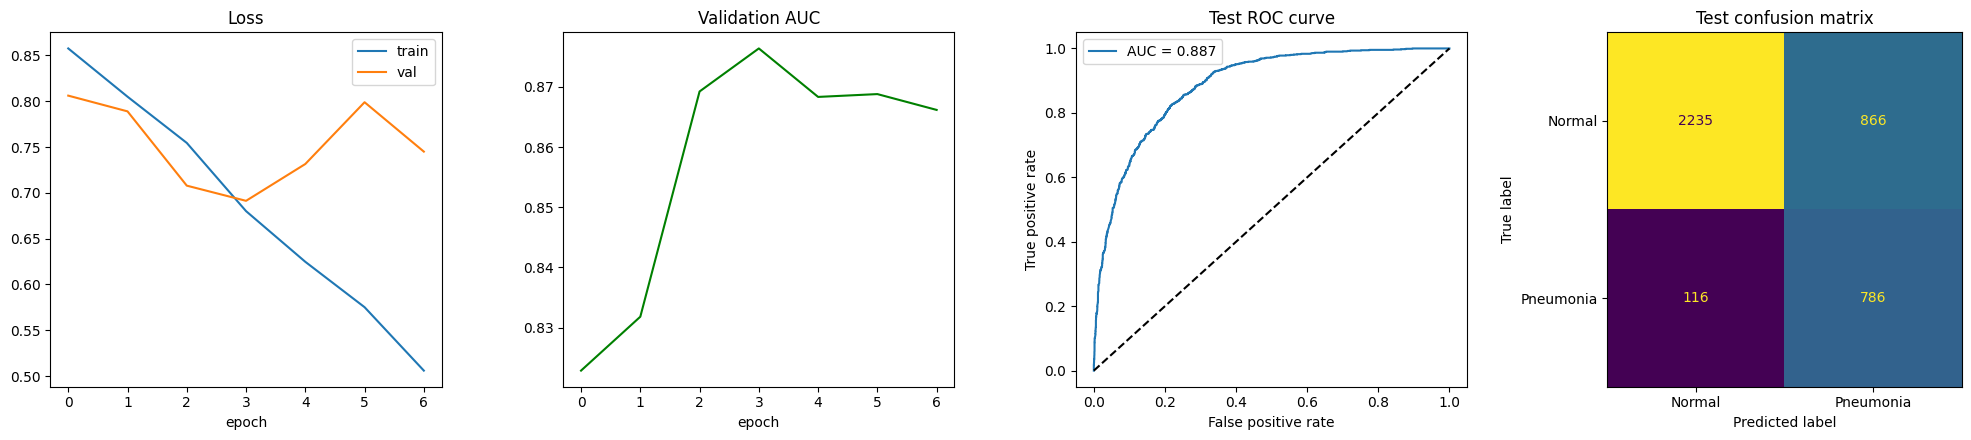

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, accuracy_score)

model.load_state_dict(torch.load(MODELS / "best_model.pt", map_location=device))

# 1) Choose the threshold on VALIDATION data (best sensitivity + specificity balance)
vp, vl = predict(val_loader)
fpr, tpr, thr = roc_curve(vl, vp)
threshold = float(thr[np.argmax(tpr - fpr)])

# 2) Report on the untouched TEST set
tp_, tl = predict(test_loader)
pred = (tp_ >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(tl, pred).ravel()
metrics = dict(
    test_auc=float(roc_auc_score(tl, tp_)), threshold=threshold,
    accuracy=float(accuracy_score(tl, pred)),
    sensitivity=float(tp / (tp + fn)), specificity=float(tn / (tn + fp)),
    precision=float(precision_score(tl, pred)), f1=float(f1_score(tl, pred)),
    tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
    model="DenseNet121 (ImageNet pretrained), RSNA Pneumonia, 224x224")
json.dump(metrics, open(RESULTS / "metrics.json", "w"), indent=2)
for k, v in metrics.items():
    print(f"{k:12s}: {round(v, 4) if isinstance(v, float) else v}")

# 3) Plots
h = history
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
ax[0].plot([r["train_loss"] for r in h], label="train"); ax[0].plot([r["val_loss"] for r in h], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot([r["val_auc"] for r in h], color="green"); ax[1].set_title("Validation AUC"); ax[1].set_xlabel("epoch")
fp_, tp_r, _ = roc_curve(tl, tp_)
ax[2].plot(fp_, tp_r, label=f"AUC = {metrics['test_auc']:.3f}"); ax[2].plot([0, 1], [0, 1], "k--")
ax[2].set_title("Test ROC curve"); ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate"); ax[2].legend()
ConfusionMatrixDisplay(confusion_matrix(tl, pred), display_labels=["Normal", "Pneumonia"]).plot(ax=ax[3], colorbar=False)
ax[3].set_title("Test confusion matrix")
plt.tight_layout()
plt.savefig(RESULTS / "training_results.png", dpi=120)
plt.show()